In [176]:
from selecao_e_preparacao import buildDataset, filterDataset
import matplotlib.pyplot as plt
import numpy as np

# EXPERIMENTO 1: DRONE SAUDÁVEL
Para este experimento, repete-se a utilização de um drone saudável. Ou seja, iremos usar a categoria f0. Porém, agora aplicando FFT no sinal, o levando para o domínio da frequência.
Segue abaixo a tabela com todas as especificações que utilizaremos para este experimento:

| Registro | Condição | Severidade | Velocidade (`SP`) | Canal (`C`) | Repetição | Amostras | Frequência | Duração | Por que podem ser comparados |
|---|---|---:|---:|---:|---:|---:|---:|---:|---|
| `F0_SV0_SP1_C1_R1.mat` | Saudável | 0 | 1 | 1 | 1 | 600.000 | 10.000 Hz | 60 s | Mesmas condições experimentais |

In [177]:
dataset = buildDataset()    # carrega todo o dataset

In [178]:
dataset_f0 = filterDataset( # filtra com base nos parâmetros definidos.
    dataset=dataset,
    condition=0,
    severity=0,
    speed=1,
    channel=1,
    recording=1,
)

In [179]:
#nesse bloco vamos criar uma função que automaticamente plota o dataset filtrado quando chamada.
# ela obviamente vai ser reutilizada a posteriori.

def plotDataset(filtered_dataset):

    figure, axis = plt.subplots(figsize=(12, 4))

    for record in filtered_dataset:
        acceleration = np.asarray(record[0]).squeeze()
        timestamp = np.asarray(record[2]).squeeze()

        condition, severity, speed, channel, recording = record[3:8]
        label = (
            f"F{condition} SV{severity} SP{speed} "
            f"C{channel} R{recording}"
        )
        axis.plot(timestamp, acceleration, label=label)

    axis.set_title("Sinal de aceleração no domínio do tempo")
    axis.set_xlabel("Tempo (s)")
    axis.set_ylabel("Aceleração")

    axis.legend()

    axis.grid(True)
    figure.tight_layout()
    plt.show()

    return figure, axis



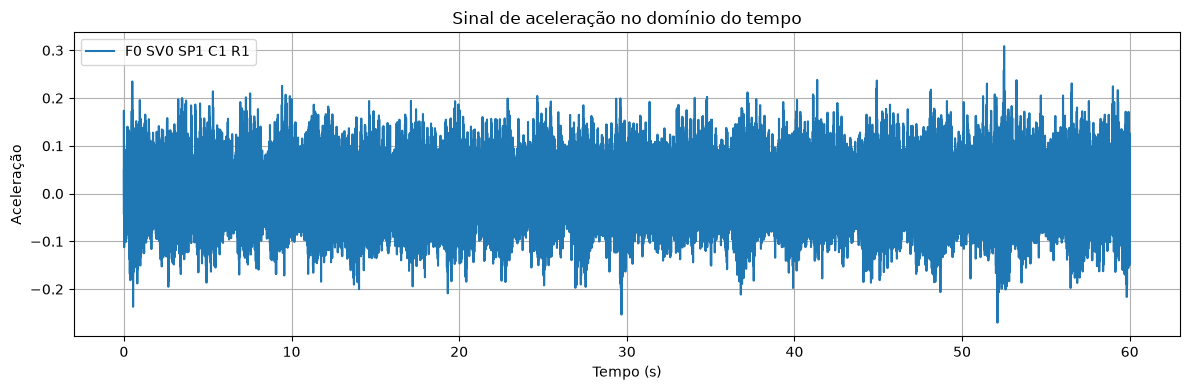

(<Figure size 1200x400 with 1 Axes>,
 <Axes: title={'center': 'Sinal de aceleração no domínio do tempo'}, xlabel='Tempo (s)', ylabel='Aceleração'>)

In [180]:
# agora vamos plotar o nosso sinal cujos parâmetros foram definidos na tabela:

plotDataset(dataset_f0)

In [181]:
# LKKKKKKKKKK ok talvez deveríamos usar uma escala de tempo menor para visualizar ...

def filterDatasetByTimeInterval(dataset, start_time, end_time):
    filtrado = []

    for record in dataset:
        acceleration = np.asarray(record[0]).squeeze()
        timestamp = np.asarray(record[2]).squeeze()

        intervalo = (timestamp >= start_time) & (timestamp <= end_time)
        if not np.any(intervalo):
            continue

        samples = np.flatnonzero(intervalo)
        sample_1 = samples[0]
        sample_f = samples[-1] + 1

        filtrado_r = list(record)
        filtrado_r[0] = acceleration[sample_1:sample_f]
        filtrado_r[2] = timestamp[sample_1:sample_f]

        filtrado.append(filtrado_r)

    return filtrado

In [182]:
dataset_f0_small = filterDatasetByTimeInterval(dataset=dataset_f0,
                                               start_time=dataset_f0[0][2].min(),
                                               end_time=dataset_f0[0][2].min()+0.2)

Observamos acima o padrão típico das oscilações para hélices saudáveis.

In [183]:
def plot_fft(datasets, fs=10000):
    plt.figure(figsize=(12, 4))

    for record in datasets:
        signal = np.asarray(record[0]).squeeze()

        N = len(signal)
        signal = signal - np.mean(signal)

        janela = np.hanning(N)
        fft = np.fft.rfft(signal * janela)
        frequencias = np.fft.rfftfreq(N, d=1/fs)
        amplitude = 2 * np.abs(fft) / np.sum(janela)

        condition, severity, speed, channel, recording = record[3:8]
        label = f"F{condition} SV{severity} SP{speed} C{channel} R{recording}"

        plt.plot(frequencias, amplitude, label=label)

    plt.title("Comparação dos espectros de frequência")
    plt.xlabel("Frequência (Hz)")
    plt.ylabel("Amplitude (g)")
    plt.legend()
    plt.grid(True)
    plt.xlim(0, fs / 2)
    plt.tight_layout()
    plt.show()

def FFT_analysis(signal, dataset):
    # Parâmetros de aquisição 
    fs = 1000.0  # Taxa de amostragem em Hz (1KHz segundo o artigo do DronePropA)
    T = 1.0 / fs  # Período de amostragem
    N = dataset.shape[0]  # Número de amostras no sinal
    t = np.linspace(0.0, N * T, N, endpoint=False)

    # Pré-processamento: Remover componente DC (média / gravidade)
    signal_sem_dc = signal - np.mean(signal)

    # Aplicar janela de Hann (reduz distorções nas bordas do sinal)
    janela = np.hanning(N)
    sinal_janelado = signal_sem_dc * janela

    # Calcular o FFT com numpy (usando rfft pois o sinal é real)
    amplitudes = np.fft.rfft(sinal_janelado)
    frequencias = np.fft.rfftfreq(N, d=T)

    # 5. Calcular a amplitude real (normalizada e compensando a janela de Hann)
    amplitude = (2.0 / N) * np.abs(amplitudes) * 2.0  # Fator 2 extra compensa a janela de Hann

    return amplitudes, frequencias

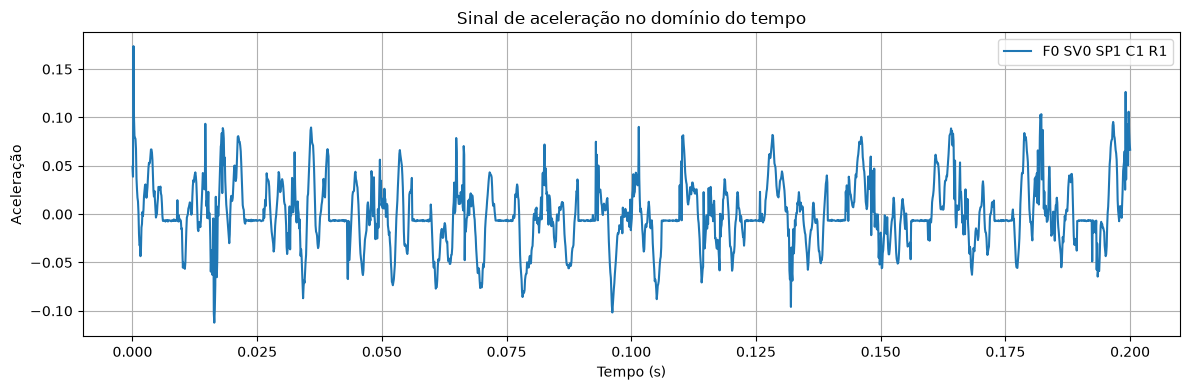

(<Figure size 1200x400 with 1 Axes>,
 <Axes: title={'center': 'Sinal de aceleração no domínio do tempo'}, xlabel='Tempo (s)', ylabel='Aceleração'>)

In [184]:
dataset_f0_small = filterDatasetByTimeInterval(dataset=dataset_f0,
                                               start_time=dataset_f0[0][2].min(),
                                               end_time=dataset_f0[0][2].min()+0.2)

FFT_analysis(signal=np.asarray(dataset_f0_small[0][0]).squeeze(), dataset=dataset_f0_small[0][0])

plotDataset(dataset_f0_small)

# EXPERIMENTO 2: CONDIÇÕES DE FALHA

Aqui, iremos experimentar com a condição de falha f1, com severidade máxima.

| Registro | Condição | Severidade | Velocidade (`SP`) | Canal (`C`) | Repetição | Amostras | Frequência | Duração | Por que podem ser comparados |
|---|---|---:|---:|---:|---:|---:|---:|---:|---|
| `F1_SV1_SP1_C1.mat` | Não-saudável | 3 | 1 | 1 | 1* | 600.000 | 10.000 Hz | 60 s | Mesma velocidade, canal, frequência e duração da referência saudável |

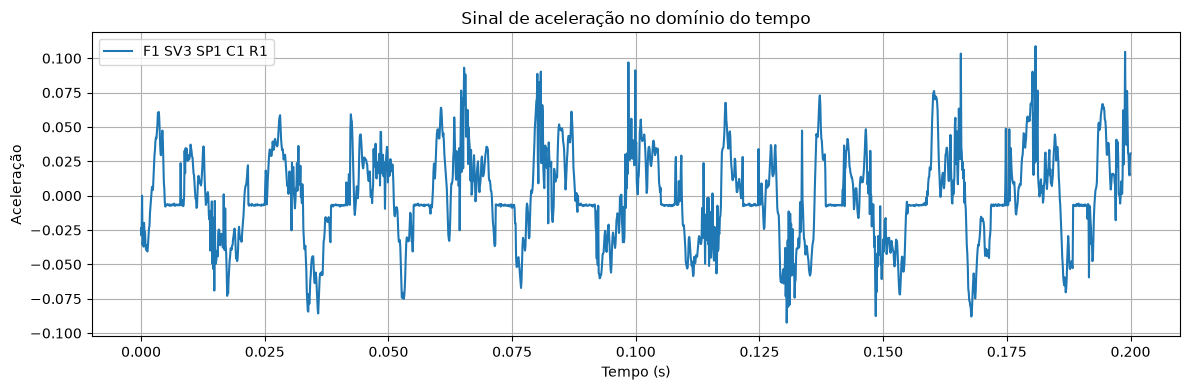

(<Figure size 1200x400 with 1 Axes>,
 <Axes: title={'center': 'Sinal de aceleração no domínio do tempo'}, xlabel='Tempo (s)', ylabel='Aceleração'>)

In [185]:
dataset_f1 = filterDataset(
    dataset=dataset,
    condition=1,
    severity=3,
    speed=1,
    channel=1,
    recording=1,
)

dataset_f1_small = filterDatasetByTimeInterval(dataset=dataset_f1,
                                               start_time=dataset_f1[0][2].min(),
                                               end_time=dataset_f1[0][2].min()+0.2)

FFT_analysis(signal=np.asarray(dataset_f1_small[0][0]).squeeze(), dataset=dataset_f1_small[0][0])

plotDataset(dataset_f1_small)

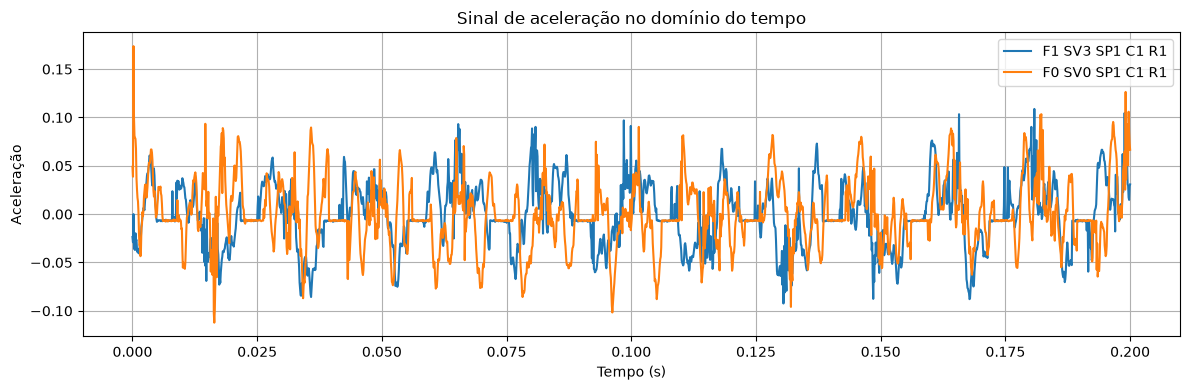

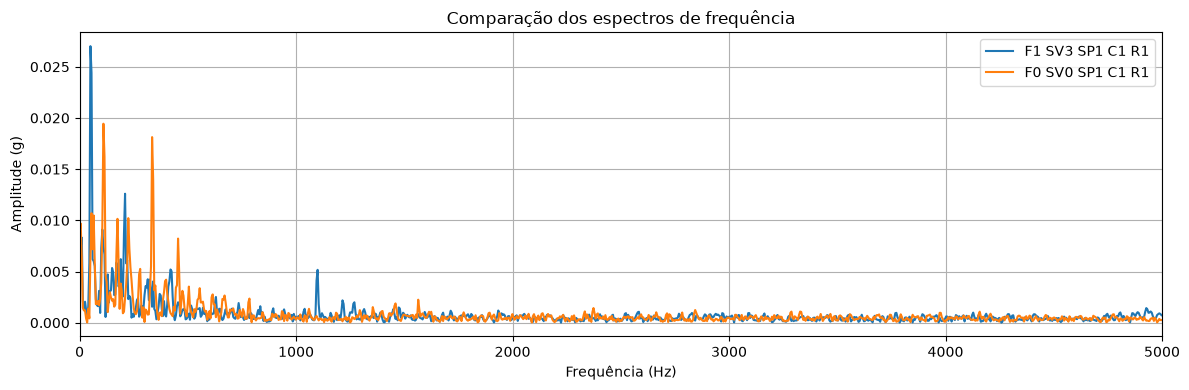

In [186]:
# show di bolations. Funcionou, agora queremos plotar os dois lado a lado. Para fazer isso, basta combinar os dois:
combined_ds = [dataset_f1_small[0], dataset_f0_small[0]]

plotDataset(combined_ds)

signal = np.asarray(combined_ds[0][0]).squeeze()
FFT_analysis(signal, dataset=combined_ds[0][0])
signal2 = np.asarray(combined_ds[1][0]).squeeze()
FFT_analysis(signal2, dataset=combined_ds[1][0])

plot_fft([combined_ds[0], combined_ds[1]])

Comparando as duas formas de ver os dados, nota-se que, no tempo, é muito mais difícil diferenciar as duas situações, uma com falha e a outra não. 
Porém, ao levarmos os sinais para o domínio da frequência através da Transformada Rápida de Fourier (FFT) é percebível a distinção entre as duas num espectro menor até cerca de 2KHz, com o sinal de falha tendo picos muito incomuns e diferentes entre si, como visto nas ondas de cor azul.

# Extração de Informações

Nesta etapa, iremos extrair informações importantes para nossa análise, como calcular a frequeência dominante, a magnitude do pico dominante, potência do sinal, centróide e entropia espectral dos nossos sinais, para que com estes valores, possamos diferenciar situações distintas do sensoriamento do drone, e posteriormente, treinarmos um modelo de machine learning com essas informações, para que seja capaz de classificar situação/severidade a partir do sinal de entrada de um drone qualquer.

In [187]:
def frequencia_dominante(signal, dataset):
    fft_valores, frequencias = FFT_analysis(signal, dataset)
    indice_max = np.argmax(np.abs(fft_valores))
    frequencia_dominante = frequencias[indice_max]
    return frequencia_dominante

#Recebe-se os valores do espectro de frequência e as frequências correspondentes para cada sinal.
amplitudes_signal1, frequencias_signal1 = FFT_analysis(signal, dataset=combined_ds[0][0])
amplitudes_signal2, frequencias_signal2 = FFT_analysis(signal2, dataset=combined_ds[1][0])

#Calcula-se o índice da frequência dominante para cada sinal.
frequencias_dominantes_signal1 = frequencia_dominante(signal, dataset=combined_ds[0][0])
frequencias_dominantes_signal2 = frequencia_dominante(signal2, dataset=combined_ds[1][0])

print(f"Frequência dominante do sinal F1: {frequencias_dominantes_signal1:.2f} Hz")
print(f"Frequência dominante do sinal F2: {frequencias_dominantes_signal2:.2f} Hz")

Frequência dominante do sinal F1: 5.00 Hz
Frequência dominante do sinal F2: 10.99 Hz


In [188]:
#Calcula-se a magnitude do pico dominante para cada sinal.
magnitude_pico_dominante_signal1 = np.max(np.abs(amplitudes_signal1))
magnitude_pico_dominante_signal2 = np.max(np.abs(amplitudes_signal2))

print(f"Magnitudes dos picos dominantes: Sinal F1 = {magnitude_pico_dominante_signal1:.2f}, Sinal F2 = {magnitude_pico_dominante_signal2:.2f}")

Magnitudes dos picos dominantes: Sinal F1 = 13.51, Sinal F2 = 9.72


In [189]:
#Calcula-se a potencia média do sinal no domínio da frequência para cada sinal.
potencia_media_signal1 = np.mean(np.abs(amplitudes_signal1)**2)
potencia_media_signal2 = np.mean(np.abs(amplitudes_signal2)**2)

print(f"Potência média no domínio da frequência: Sinal F1 = {potencia_media_signal1:.2f}, Sinal F2 = {potencia_media_signal2:.2f}")

Potência média no domínio da frequência: Sinal F1 = 0.77, Sinal F2 = 0.78


In [190]:
#Calcula-se o centroide do espectro de frequência para cada sinal.
centroide_signal1 = np.sum(frequencias_signal1 * np.abs(amplitudes_signal1)) / np.sum(np.abs(amplitudes_signal1))
centroide_signal2 = np.sum(frequencias_signal2 * np.abs(amplitudes_signal2)) / np.sum(np.abs(amplitudes_signal2))

print(f"Centroide do espectro de frequência: Sinal F1 = {centroide_signal1:.2f} Hz, Sinal F2 = {centroide_signal2:.2f} Hz")

Centroide do espectro de frequência: Sinal F1 = 153.54 Hz, Sinal F2 = 145.01 Hz


In [191]:
entropia_espectral_signal1 = -np.sum((np.abs(amplitudes_signal1)**2 / np.sum(np.abs(amplitudes_signal1)**2)) * np.log2(np.abs(amplitudes_signal1)**2 / np.sum(np.abs(amplitudes_signal1)**2)))
entropia_espectral_signal2 = -np.sum((np.abs(amplitudes_signal2)**2 / np.sum(np.abs(amplitudes_signal2)**2)) * np.log2(np.abs(amplitudes_signal2)**2 / np.sum(np.abs(amplitudes_signal2)**2)))

print(f"Entropia espectral: Sinal F1 = {entropia_espectral_signal1:.2f}, Sinal F2 = {entropia_espectral_signal2:.2f}")

Entropia espectral: Sinal F1 = 5.30, Sinal F2 = 5.81
